# Bank Customer Satisfaction Analysis – Sample Data Analyst Project
**Audience:** B.Tech 1st Year students (Data Analyst track) | **Tools:** Python, pandas, matplotlib, seaborn

## 1. Business problem
The bank wants to understand **what drives customer satisfaction** so that relationship managers can support at-risk customers early.

**Questions we will answer**
1. What does the satisfaction score look like overall?
2. Do tenure and complaints affect satisfaction?
3. Does satisfaction differ by account type, city, preferred channel or credit card?
4. Which customers are at risk (satisfaction score below 50)?

> The dataset is **synthetic** (computer-generated) and contains no real customer data.

## 2. Import libraries

In [33]:
%pip install pandas


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi']=100

ImportError: DLL load failed while importing _mt19937: An Application Control policy has blocked this file.

In [40]:
#   Find the number of rows?

import csv
with open("bank_data_clean.csv", newline="", encoding="utf-8") as f:
    rows=list(csv.DictReader(f))
    

print("number of rows:", len(rows))

FileNotFoundError: [Errno 2] No such file or directory: 'bank_data_clean.csv'

## 3. Load and inspect the data

In [32]:
import pandas as pd
df = pd.read_csv('bank_data(1).csv')
print('Rows, Columns:', df.shape)
df.head()

ImportError: DLL load failed while importing _mt19937: An Application Control policy has blocked this file.

In [ ]:
df.info()

NameError: name 'df' is not defined

In [ ]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum()>0])
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().round(1)

Missing values per column:
City                  4
Preferred_Channel     5
Monthly_Income_INR    6
Tenure_Years          5
dtype: int64

Duplicate rows: 5


,Age,Monthly_Income_INR,Tenure_Years,Complaints_Last_Year,Satisfaction_Score
count,255.0,249.0,250.0,255.0,255.0
mean,38.5,47560.2,6.4,1.3,62.8
std,14.3,28660.8,4.0,1.1,11.5
min,-28.0,5000.0,0.5,0.0,31.0
25%,28.0,27500.0,3.5,0.0,55.2
50%,39.0,42500.0,6.0,1.0,62.8
75%,46.5,61500.0,8.6,2.0,70.8
max,150.0,182500.0,24.0,6.0,95.4


**What we found:** some missing values (`City`, `Preferred_Channel`, `Monthly_Income_INR`, `Tenure_Years`), duplicate rows, inconsistent text in `Account_Type` (e.g. `savings`, `SALARY`, ` Savings`) and impossible `Age` values (a negative age and an age above 100). We clean these next.

## 4. Clean the data

In [ ]:
clean = df.copy()
# 1. Remove duplicate rows
clean = clean.drop_duplicates()
# 2. Standardise text
clean['Account_Type'] = clean['Account_Type'].str.strip().str.title()
# 3. Fix impossible values (customer age must be between 21 and 70)
clean.loc[(clean['Age']<21)|(clean['Age']>70),'Age'] = np.nan
# 4. Fill missing numbers with the median (robust to outliers)
num_cols = ['Age','Monthly_Income_INR','Tenure_Years','Complaints_Last_Year']
for c in num_cols:
    clean[c] = clean[c].fillna(clean[c].median())
clean[['Age','Monthly_Income_INR']] = clean[['Age','Monthly_Income_INR']].round().astype(int)
# 5. Fill missing categories with the most common value (mode)
for c in ['City','Preferred_Channel']:
    clean[c] = clean[c].fillna(clean[c].mode()[0])
# 6. Convert the date column to a proper date type
clean['Last_Activity_Date'] = pd.to_datetime(clean['Last_Activity_Date'])
print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())

NameError: name 'df' is not defined

## 5. Create new columns (feature engineering)

In [ ]:
clean['Complaints_Per_Tenure_Year'] = (clean['Complaints_Last_Year']/clean['Tenure_Years']).round(2)
def band(s):
    if s>=75: return 'Very Satisfied'
    if s>=60: return 'Satisfied'
    if s>=50: return 'Neutral'
    return 'At Risk'
clean['Satisfaction_Band'] = clean['Satisfaction_Score'].apply(band)
clean['Tenure_Band'] = pd.cut(clean['Tenure_Years'],[0,2,5,10,25],labels=['<2 yrs','2-5 yrs','5-10 yrs','10+ yrs'])
clean[['Customer_ID','Complaints_Per_Tenure_Year','Satisfaction_Band','Tenure_Band']].head()

,Customer_ID,Complaints_Per_Tenure_Year,Satisfaction_Band,Tenure_Band
0,C1067,0.22,Neutral,2-5 yrs
1,C1127,2.00,Satisfied,<2 yrs
2,C1073,0.00,Neutral,2-5 yrs
3,C1157,0.08,Very Satisfied,10+ yrs
4,C1017,0.30,Satisfied,5-10 yrs


## 6. Exploratory data analysis (EDA)

### Q1. Overall satisfaction

count    250.0
mean      62.9
std       11.6
min       31.0
25%       55.3
50%       62.8
75%       70.8
max       95.4
Name: Satisfaction_Score, dtype: float64


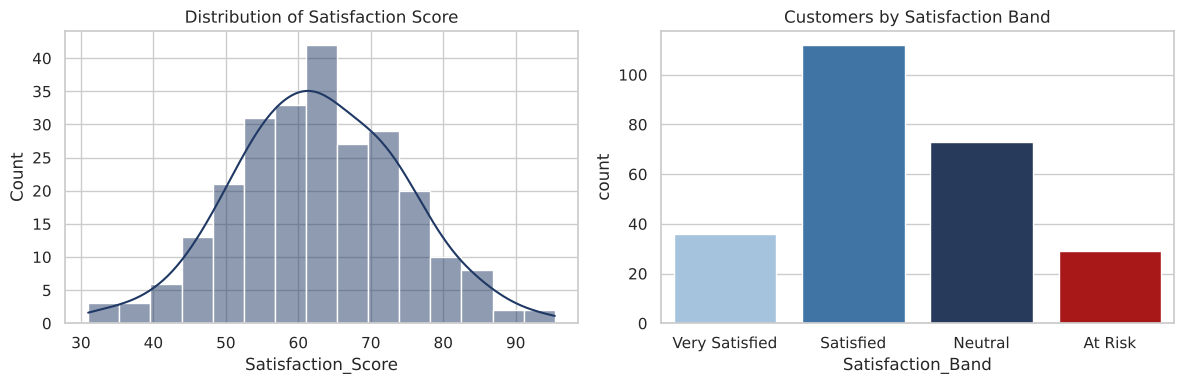

In [ ]:
print(clean['Satisfaction_Score'].describe().round(1))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(clean['Satisfaction_Score'],bins=15,kde=True,color='#1F3864',ax=ax[0]);ax[0].set_title('Distribution of Satisfaction Score')
order=['Very Satisfied','Satisfied','Neutral','At Risk']
sns.countplot(data=clean,x='Satisfaction_Band',hue='Satisfaction_Band',legend=False,order=order,palette=['#1F3864','#2E75B6','#9DC3E6','#C00000'],ax=ax[1]);ax[1].set_title('Customers by Satisfaction Band')
plt.tight_layout();plt.savefig('../images/01_overall_satisfaction.png');plt.show()

### Q2. Do tenure and complaints affect satisfaction?

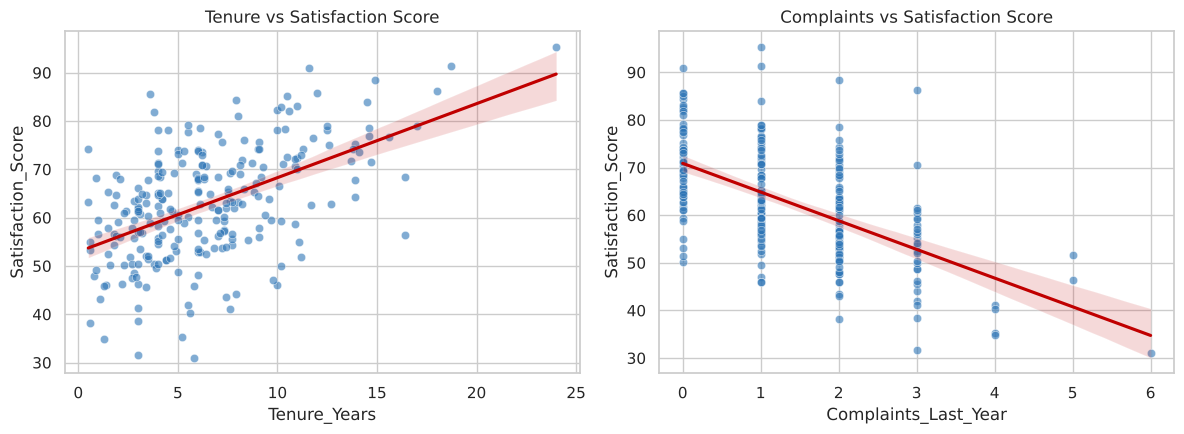

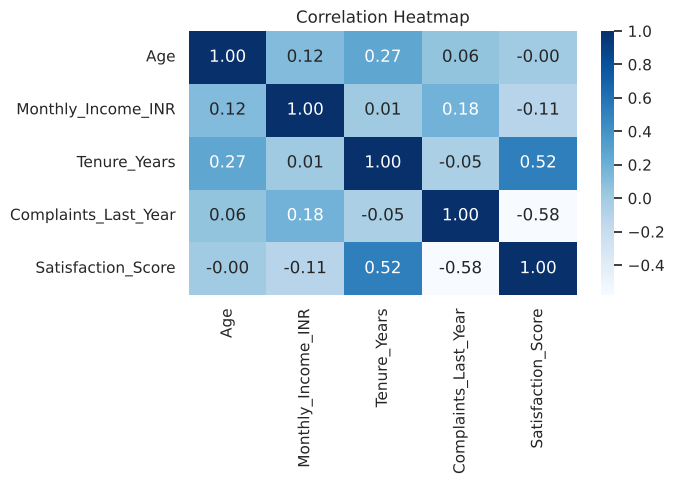

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
sns.scatterplot(data=clean,x='Tenure_Years',y='Satisfaction_Score',alpha=.6,color='#2E75B6',ax=ax[0])
sns.regplot(data=clean,x='Tenure_Years',y='Satisfaction_Score',scatter=False,color='#C00000',ax=ax[0]);ax[0].set_title('Tenure vs Satisfaction Score')
sns.scatterplot(data=clean,x='Complaints_Last_Year',y='Satisfaction_Score',alpha=.6,color='#2E75B6',ax=ax[1])
sns.regplot(data=clean,x='Complaints_Last_Year',y='Satisfaction_Score',scatter=False,color='#C00000',ax=ax[1]);ax[1].set_title('Complaints vs Satisfaction Score')
plt.tight_layout();plt.savefig('../images/02_tenure_complaints.png');plt.show()
plt.figure(figsize=(7,5))
sns.heatmap(clean[num_cols+['Satisfaction_Score']].corr().round(2),annot=True,cmap='Blues',fmt='.2f');plt.title('Correlation Heatmap')
plt.tight_layout();plt.savefig('../images/03_correlation.png');plt.show()

In [ ]:
print(clean.groupby('Tenure_Band',observed=True)['Satisfaction_Score'].agg(['count','mean']).round(1))
print(clean.groupby('Complaints_Last_Year')['Satisfaction_Score'].agg(['count','mean']).round(1))

             count  mean
Tenure_Band             
<2 yrs          25  55.3
2-5 yrs         84  59.2
5-10 yrs        96  62.9
10+ yrs         45  73.8
                      count  mean
Complaints_Last_Year             
0                        65  70.8
1                        82  64.7
2                        69  59.2
3                        27  53.4
4                         4  37.9
5                         2  49.0
6                         1  31.0


### Q3. Does satisfaction differ by account type, city, preferred channel or credit card?

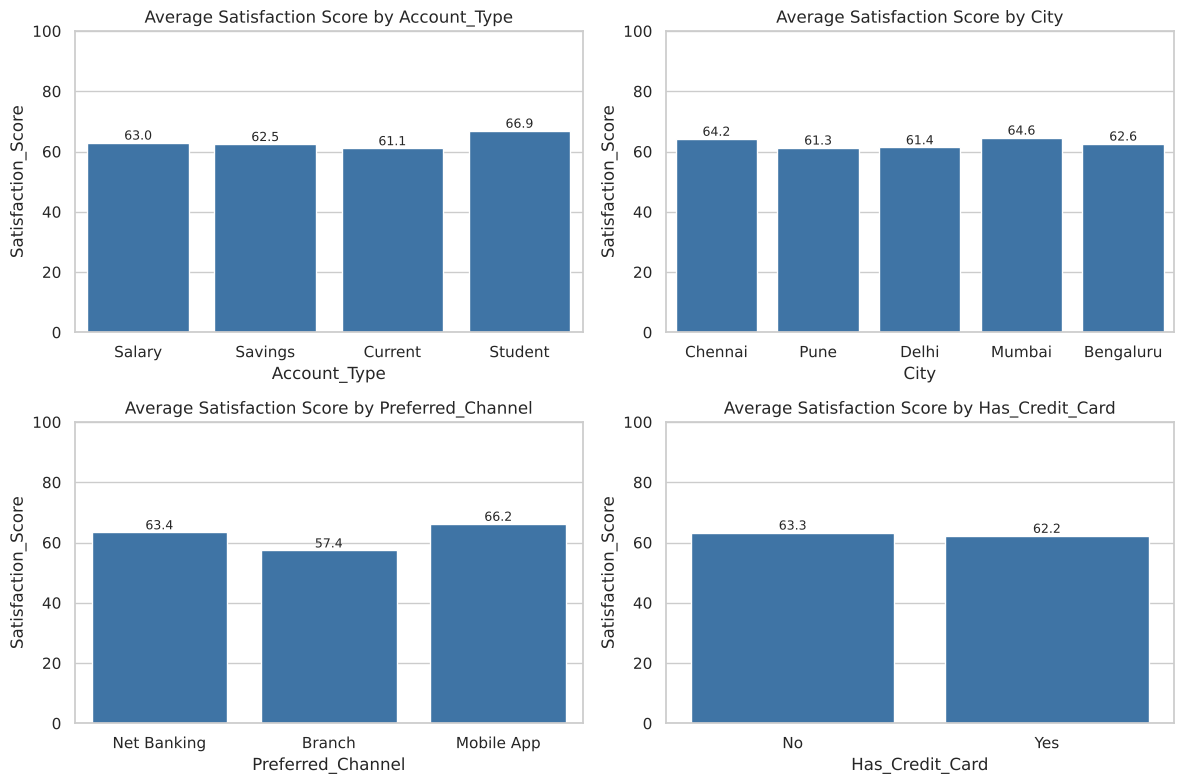

In [ ]:
fig,ax=plt.subplots(2,2,figsize=(12,8))
for a,col in zip(ax.flat,['Account_Type','City','Preferred_Channel','Has_Credit_Card']):
    sns.barplot(data=clean,x=col,y='Satisfaction_Score',errorbar=None,color='#2E75B6',ax=a)
    a.set_title(f'Average Satisfaction Score by {col}');a.set_ylim(0,100)
    for p in a.patches:a.annotate(f'{p.get_height():.1f}',(p.get_x()+p.get_width()/2,p.get_height()),ha='center',va='bottom',fontsize=9)
plt.tight_layout();plt.savefig('../images/04_group_comparison.png');plt.show()

### Q4. Which customers are at risk?

In [ ]:
risk = clean[clean['Satisfaction_Band']=='At Risk'].sort_values('Satisfaction_Score')
print(f'{len(risk)} customers ({len(risk)/len(clean):.1%}) are At Risk')
print('Average complaints of At Risk customers:', round(risk['Complaints_Last_Year'].mean(),1),'vs overall', round(clean['Complaints_Last_Year'].mean(),1))
print('Average tenure of At Risk customers:', round(risk['Tenure_Years'].mean(),1),'years vs overall', round(clean['Tenure_Years'].mean(),1),'years')
risk[['Customer_ID','City','Preferred_Channel','Tenure_Years','Complaints_Last_Year','Satisfaction_Score']].head(10)

29 customers (11.6%) are At Risk
Average complaints of At Risk customers: 2.7 vs overall 1.3
Average tenure of At Risk customers: 4.1 years vs overall 6.5 years


,Customer_ID,City,Preferred_Channel,Tenure_Years,Complaints_Last_Year,Satisfaction_Score
180,C1130,Pune,Branch,5.8,6,31.0
226,C1169,Delhi,Branch,3.0,3,31.6
220,C1224,Mumbai,Branch,1.3,4,34.9
62,C1020,Mumbai,Mobile App,5.2,4,35.3
87,C1091,Delhi,Branch,0.6,2,38.2
187,C1156,Bengaluru,Branch,3.0,3,38.5
143,C1089,Bengaluru,Branch,5.6,4,40.3
54,C1033,Delhi,Net Banking,7.6,4,41.1
250,C1148,Delhi,Branch,3.0,3,41.2
214,C1036,Mumbai,Net Banking,5.5,3,42.0


## 7. Key insights (generated from the data)

In [ ]:
r_ten=clean['Tenure_Years'].corr(clean['Satisfaction_Score']);r_cmp=clean['Complaints_Last_Year'].corr(clean['Satisfaction_Score'])
best=clean.groupby('Preferred_Channel')['Satisfaction_Score'].mean().idxmax();worst=clean.groupby('Preferred_Channel')['Satisfaction_Score'].mean().idxmin()
card=clean.groupby('Has_Credit_Card')['Satisfaction_Score'].mean()
print(f"1. Average satisfaction score: {clean['Satisfaction_Score'].mean():.1f}; median {clean['Satisfaction_Score'].median():.1f}.")
print(f"2. Tenure vs satisfaction correlation = {r_ten:.2f} (positive); complaints vs satisfaction = {r_cmp:.2f} (negative).")
print(f"3. Highest-scoring channel: {best}; lowest: {worst}.")
print(f"4. Customers with a credit card average {card['Yes']:.1f} vs {card['No']:.1f} without.")
print(f"5. {len(risk)} customers are At Risk; they logged {risk['Complaints_Last_Year'].mean():.1f} complaints on average vs {clean['Complaints_Last_Year'].mean():.1f} overall.")

1. Average satisfaction score: 62.9; median 62.8.
2. Tenure vs satisfaction correlation = 0.52 (positive); complaints vs satisfaction = -0.58 (negative).
3. Highest-scoring channel: Mobile App; lowest: Branch.
4. Customers with a credit card average 62.2 vs 63.3 without.
5. 29 customers are At Risk; they logged 2.7 complaints on average vs 1.3 overall.


## 8. Recommendations
- Relationship managers should **track complaints** and contact customers who log 2 or more in a year.
- Run **welcome and loyalty programmes** for customers in their first two years, since satisfaction rises with tenure.
- Review **service quality in the lowest-scoring channel** and offer **follow-up calls** to customers flagged At Risk.

> **Remember:** correlation does not prove causation. This analysis shows association, not cause.

## 9. Save the cleaned data

In [ ]:
clean.to_csv('../data/processed/bank_data_clean.csv',index=False)
print('Saved cleaned file with', len(clean), 'rows')

Saved cleaned file with 250 rows
